# Yak: MLM pretraining (self-contained Colab notebook)

Everything lives in this one notebook: the model classes, masking, training loop and a fast BPE encoder. It does not import anything from the Yak repo. You provide two things:

- `bpe.json`: the trained tokenizer file (keys `tok2id`, `merges`, `special_tokens`).
- A plain text training file, one paragraph per line (the `wikitext103_train.txt` your tokenizer notebook wrote is exactly this). A separate validation text file is optional.

**Where to put the files.** Best is Google Drive, e.g. `MyDrive/yak/bpe.json` and `MyDrive/yak/wikitext103_train.txt`, then set the paths in the "Files" cell. If a path is wrong the notebook opens an upload dialog instead (fine for `bpe.json`, slow for a 500 MB text file). Tokenized data and checkpoints are written to `MyDrive/yak`, so a disconnect only costs you the steps since the last checkpoint.

**Order of cells**
1. Setup and GPU check.
2. Model code (embedding, attention, feed-forward, encoder block, MLM model).
3. Config, then Files.
4. Tokenizer: loads `bpe.json`, builds a fast encoder, checks it against the original algorithm.
5. Data: tokenizes once, caches ids on Drive, holds out a validation split by article.
6. Model build and sanity checks (parameter count, starting loss, masking rate, overfit one batch).
7. Training with resume, validation and best-checkpoint saving.
8. Checks: reload the best checkpoint, fill-the-mask samples, loss curves.

In [2]:
import os, sys, math, time, json, re, copy, random
from types import SimpleNamespace
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

assert torch.cuda.is_available(), "No GPU. Runtime > Change runtime type > GPU, then re-run."
print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__)

from google.colab import drive
drive.mount("/content/drive")

WORK_DIR = "/content/drive/MyDrive/yak"      # tokenized data + checkpoints persist here
os.makedirs(WORK_DIR, exist_ok=True)

!pip install -q tqdm

GPU: Tesla T4 | torch 2.11.0+cu130


MessageError: Error: credential propagation was unsuccessful

In [22]:
# Model code: identical to the repo files on feature/mlm, inlined so no imports are needed.
class FFN(nn.Module):
    """Feed Forward Network module
    Args:
        d_model: dimension of the model
        d_ff: dimension of the feed forward network
        dropout: dropout rate
    """
    def __init__(self,d_model:int,dropout:float=0.1,ff_multiplier:int=4):
        super().__init__()
        self.d_model = d_model
        self.d_ff = d_model * ff_multiplier
        self.linear1 = nn.Linear(d_model, self.d_ff)
        self.linear2 = nn.Linear(self.d_ff, d_model)
        self.dropout = nn.Dropout(dropout)
        self.activation = nn.GELU()

    def forward(self,x:torch.Tensor) -> torch.Tensor:
        x = self.linear1(x)
        x = self.activation(x)
        x = self.linear2(x)
        x = self.dropout(x)
        return x


class BiDirectionalAttention(nn.Module):
    """Multi head bidirectional self-attention.

    Same interface and maths as before, but uses F.scaled_dot_product_attention so the
    (seq_len x seq_len) score matrix is never fully materialised. That matters at the
    2,048 token context.

    Args:
        d_model: dimension of the model
        nhead: number of heads
        dropout: attention dropout rate
    """

    def __init__(self, d_model: int, nhead: int, dropout: float = 0.1):
        super().__init__()
        assert d_model % nhead == 0, "d_model must be divisible by nhead"
        self.d_model = d_model
        self.nhead = nhead
        self.d_k = d_model // nhead
        self.dropout_p = dropout

        self.qkv_proj = nn.Linear(d_model, d_model * 3)
        self.out_proj = nn.Linear(d_model, d_model)

    def forward(self, x: torch.Tensor, padding_mask: torch.Tensor | None = None) -> torch.Tensor:
        """
        Args:
            x: (batch_size, seq_len, d_model)
            padding_mask: optional (batch_size, seq_len), True/1 for real tokens, False/0 for padding
        Returns:
            (batch_size, seq_len, d_model)
        """
        batch_size, seq_len, _ = x.size()
        qkv = self.qkv_proj(x).view(batch_size, seq_len, 3, self.nhead, self.d_k)
        qkv = qkv.permute(2, 0, 3, 1, 4)  # (3, B, nhead, L, d_k)
        q, k, v = qkv[0], qkv[1], qkv[2]

        attn_mask = None
        if padding_mask is not None:
            attn_mask = padding_mask.bool()[:, None, None, :]  # (B, 1, 1, L), True = may attend

        out = F.scaled_dot_product_attention(
            q, k, v,
            attn_mask=attn_mask,
            dropout_p=self.dropout_p if self.training else 0.0,
        )  # (B, nhead, L, d_k)
        out = out.transpose(1, 2).reshape(batch_size, seq_len, self.d_model)
        return self.out_proj(out)


class EncoderBlock(nn.Module):
    """Pre norm encoder block with multi head attention and feed forward network
    x = x+attebtion(LayerNorm(x),mask)
    x = x+FFN(LayerNorm(x))

    Args:
        d_model: dimension of the model
        nhead: number of heads
        dropout: dropout rate
    Shape:
        - Input: (batch_size, seq_len, d_model)
        - Output: (batch_size, seq_len, d_model)
    """
    def __init__(self,d_model:int,nhead:int,dropout:float=0.1):
        super().__init__()
        self.d_model = d_model
        self.nhead = nhead
        self.dropout = dropout

        self.attention = BiDirectionalAttention(d_model,nhead,dropout)
        self.ffn = FFN(d_model,dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self,x:torch.Tensor,padding_mask:torch.Tensor| None = None) -> torch.Tensor:
        """Feed forward pass of the encoder block
        Args:
            x: input tensor of shape (batch_size, seq_len, d_model)
            padding_mask: optional mask tensor of shape (batch_size, seq_len)
        Returns:
            output tensor of shape (batch_size, seq_len, d_model)
        """
        # Sub 1: Normalize -> Attention (mask goes here only for the attention) -> Skip connection
        x_norm = self.norm1(x)
        attn_output = self.attention(x_norm,padding_mask)
        x = x + attn_output

        # Sub 2: Normalize -> Feed Forward -> Skip connection
        x_norm = self.norm2(x)
        ffn_output = self.ffn(x_norm)
        x = x + ffn_output
        return x



class EmbedPos(nn.Module):
    """Token embedding + static sinusoidal positions (sin/cos), followed by dropout.

    Token embeddings are initialised with std = d_model ** -0.5 and scaled by
    sqrt(d_model) in forward, so they have unit scale and are not drowned out by the
    +-1 positional signal. The same init keeps the tied output head's starting
    logits small, so the initial loss lands near ln(vocab_size).

    Args:
        vocab_size: number of token ids (len(tok2id), including special tokens)
        d_model: model width (must be even)
        max_len: length of the sinusoidal table
        pad_id: id of the padding token
        dropout: dropout rate applied to the summed embedding
    """

    def __init__(self, vocab_size, d_model=256, max_len=2048, pad_id=0, dropout=0.1):
        super().__init__()
        assert d_model % 2 == 0, "d_model must be even for sin/cos pairs"
        self.vocab_size = vocab_size
        self.d_model = d_model
        self.max_len = max_len
        self.pad_id = pad_id
        self.dropout = nn.Dropout(dropout)
        self.tok_emb = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        nn.init.normal_(self.tok_emb.weight, mean=0.0, std=d_model ** -0.5)
        with torch.no_grad():
            self.tok_emb.weight[pad_id].zero_()
        # Fixed table: moves with .to(device), is not a parameter, and is not saved in checkpoints.
        self.register_buffer(
            "pos_emb", self._get_positional_encoding(max_len, d_model), persistent=False
        )

    @staticmethod
    def _get_positional_encoding(max_len, d_model):
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        return pe.unsqueeze(0)  # (1, max_len, d_model)

    def forward(self, ids):
        # ids: (batch_size, seq_len)
        seq_len = ids.size(1)
        if seq_len > self.max_len:
            raise ValueError(f"seq_len {seq_len} exceeds max_len {self.max_len}")
        tok_emb = self.tok_emb(ids) * math.sqrt(self.d_model)  # (B, L, d_model)
        emb = tok_emb + self.pos_emb[:, :seq_len, :].to(tok_emb.dtype)
        return self.dropout(emb)


class MlmModel(nn.Module):
    """Masked language model, phase 1 pre-training.

    ids -> EmbedPos -> N x EncoderBlock (pre-norm) -> final LayerNorm -> tied MLM head -> logits

    The head shares its weight with the token embedding, plus a separate output bias.

    Args:
        vocab_size: number of token ids, INCLUDING special tokens (len(tokenizer.tok2id))
        d_model: model width
        nhead: attention heads
        num_layers: number of encoder blocks
        max_seq_len: length of the sinusoidal positional table
        dropout: dropout rate
        pad_token_id: id of the padding token
    """

    def __init__(self, vocab_size: int, d_model: int, nhead: int, num_layers: int,
                 max_seq_len: int, dropout: float = 0.1, pad_token_id: int = 0):
        super().__init__()
        self.pad_id = pad_token_id
        self.vocab_size = vocab_size
        self.d_model = d_model

        self.embed = EmbedPos(vocab_size, d_model=d_model, max_len=max_seq_len,
                              pad_id=pad_token_id, dropout=dropout)
        self.blocks = nn.ModuleList(
            [EncoderBlock(d_model, nhead, dropout) for _ in range(num_layers)]
        )
        # Blocks are pre-norm, so the last residual stream must be normalised before the head.
        self.final_norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.head_bias = nn.Parameter(torch.zeros(vocab_size))

        self.apply(self._init_weights)
        # GPT-2 style: shrink the init of the two residual output projections per block.
        for name, p in self.named_parameters():
            if name.endswith("out_proj.weight") or name.endswith("linear2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * num_layers))

        emb_weight = self.embed.tok_emb.weight
        assert emb_weight.shape == (vocab_size, d_model), (
            f"Embedding weight shape {tuple(emb_weight.shape)} != {(vocab_size, d_model)}"
        )
        self.head.weight = emb_weight  # tie head to the token embedding

    def _init_weights(self, m):
        # The head is skipped: it is tied to the embedding, which EmbedPos already initialised.
        if isinstance(m, nn.Linear) and m is not self.head:
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)

    def num_parameters(self, exclude_embedding: bool = False) -> int:
        n = sum(p.numel() for p in self.parameters())  # tied weight is counted once
        if exclude_embedding:
            n -= self.embed.tok_emb.weight.numel()
        return n

    def encode(self, ids: torch.Tensor) -> torch.Tensor:
        """(batch, seq_len) ids -> (batch, seq_len, d_model) hidden states."""
        keep = ids != self.pad_id  # True for real tokens
        # Fully packed batches have no padding; skipping the mask enables the fastest attention kernels.
        padding_mask = None if bool(keep.all()) else keep
        x = self.embed(ids)
        for block in self.blocks:
            x = block(x, padding_mask)
        return self.final_norm(x)

    def _logits(self, h: torch.Tensor) -> torch.Tensor:
        return F.linear(h, self.head.weight, self.head_bias)

    def forward(self, ids: torch.Tensor, labels: torch.Tensor | None = None):
        """
        labels is None -> full logits (batch, seq_len, vocab_size), for inference.
        labels given   -> (loss, logits_at_selected_positions, targets). Only positions with
                          labels != -100 go through the vocabulary projection, which saves a
                          lot of memory (about 15% of positions instead of all of them).
        """
        h = self.encode(ids)
        if labels is None:
            return self._logits(h)
        sel = labels != -100
        targets = labels[sel]
        if targets.numel() == 0:
            return h.sum() * 0.0, None, targets
        logits = self._logits(h[sel])  # (n_selected, vocab_size)
        loss = F.cross_entropy(logits.float(), targets)
        return loss, logits, targets

In [31]:
CFG = dict(
    # model (scaled down to prevent OOM and speed up pretraining on T4)
    d_model=256, nhead=4, num_layers=6, dropout=0.1, max_seq_len=2048,
    # data / batching
    seq_len=2048,              # pretraining length
    tokens_per_step=32768,    # tokens per optimizer step, independent of seq_len
    micro_bs=16,              # reduced sequence micro-batch size for safe GPU utilization
    mask_prob=0.15,
    # optimisation
    lr=6e-4, min_lr_frac=0.1, warmup_steps=500, max_steps=12000,
    weight_decay=0.01, betas=(0.9, 0.98), grad_clip=1.0,
    # bookkeeping
    log_every=50, eval_every=500, ckpt_every=500, eval_seqs=256,
    seed=1337,
)
RESUME = True

In [25]:
# ---- Files: set these paths (Drive is best). VAL_TXT is optional. ----
BPE_PATH  = "/content/bpe.json"
TRAIN_TXT = "/content/wikitext103_train.txt"
VAL_TXT   = None        # e.g. os.path.join(WORK_DIR, "wikitext103_valid.txt"); None = hold out ~0.5% of articles from TRAIN_TXT

def locate(path, what):
    if path and os.path.exists(path):
        print(f"{what}: {path} ({os.path.getsize(path) / 1e6:.1f} MB)")
        return path
    print(f"{what} not found at {path}. Choose the file to upload.")
    from google.colab import files
    up = files.upload()
    name = next(iter(up))
    dest = os.path.abspath(name)
    print(f"{what}: using uploaded {dest}")
    return dest

BPE_PATH  = locate(BPE_PATH, "tokenizer file")
TRAIN_TXT = locate(TRAIN_TXT, "training text")
if VAL_TXT:
    VAL_TXT = locate(VAL_TXT, "validation text")

tokenizer file: /content/bpe.json (1.8 MB)
training text: /content/wikitext103_train.txt (541.1 MB)


In [26]:
with open(BPE_PATH, "r", encoding="utf-8") as f:
    _raw = json.load(f)
for k in ("tok2id", "merges", "special_tokens"):
    assert k in _raw, f"bpe.json is missing the key {k!r}"
bpe = SimpleNamespace(
    tok2id=_raw["tok2id"],
    special_tokens=_raw["special_tokens"],
    merges=[tuple(p) for p in _raw["merges"]],
)
bpe.id2tok = {i: t for t, i in bpe.tok2id.items()}

# The saved file holds 30,000 vocabulary entries PLUS 5 special tokens. The model needs all of them.
VOCAB_SIZE = len(bpe.tok2id)
assert max(bpe.tok2id.values()) + 1 == VOCAB_SIZE, "token ids are not contiguous"
assert VOCAB_SIZE < 65536, "ids must fit in uint16 for the cached arrays"
PAD, UNK, CLS, SEP, MASK = (bpe.tok2id[t] for t in ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"])
N_SPECIAL = len(bpe.special_tokens)       # ids 0..4 are special and are never masked
print(f"vocab size {VOCAB_SIZE} | merges {len(bpe.merges)} | PAD={PAD} UNK={UNK} CLS={CLS} SEP={SEP} MASK={MASK}")


class FastBPE:
    # Same result as BPE.encode_word, but applies the lowest-ranked merge present
    # instead of running every merge regex over every word, and caches per word.
    def __init__(self, bpe):
        self.rank = {tuple(p): i for i, p in enumerate(bpe.merges)}
        self.tok2id = bpe.tok2id
        self.unk = bpe.tok2id["[UNK]"]
        self.cache = {}

    def _encode(self, word):
        symbols = list(word) + ["</w>"]
        rank = self.rank
        while len(symbols) > 1:
            best, best_rank = None, None
            for i in range(len(symbols) - 1):
                r = rank.get((symbols[i], symbols[i + 1]))
                if r is not None and (best_rank is None or r < best_rank):
                    best, best_rank = (symbols[i], symbols[i + 1]), r
            if best is None:
                break
            merged, i = [], 0
            while i < len(symbols):
                if i < len(symbols) - 1 and symbols[i] == best[0] and symbols[i + 1] == best[1]:
                    merged.append(best[0] + best[1]); i += 2
                else:
                    merged.append(symbols[i]); i += 1
            symbols = merged
        return tuple(self.tok2id.get(s, self.unk) for s in symbols)

    def line_ids(self, line):
        out, cache = [], self.cache
        for w in line.split():
            t = cache.get(w)
            if t is None:
                t = cache[w] = self._encode(w)
            out.extend(t)
        return out




fast = FastBPE(bpe)


def reference_encode_word(word):
    # The original (slow) algorithm from the repo's BPE.encode_word, kept only to verify FastBPE.
    s = " ".join(list(word)) + " </w>"
    for pair in bpe.merges:
        s = re.sub(r"(?<!\S)" + re.escape(" ".join(pair)) + r"(?!\S)", "".join(pair), s)
    return [bpe.tok2id.get(t, UNK) for t in s.split()]

vocab size 30005 | merges 25022 | PAD=0 UNK=1 CLS=2 SEP=3 MASK=4


In [27]:
from array import array
from tqdm.auto import tqdm

DATA_DIR = r"/content/"
os.makedirs(DATA_DIR, exist_ok=True)
# Cache names include file sizes, so changing the text or the tokenizer never reuses stale ids.
TAG = f"{os.path.getsize(TRAIN_TXT)}_{os.path.getsize(BPE_PATH)}" + (f"_{os.path.getsize(VAL_TXT)}" if VAL_TXT else "")
TRAIN_NPY = os.path.join(DATA_DIR, f"train_{TAG}.npy")
VAL_NPY   = os.path.join(DATA_DIR, f"val_{TAG}.npy")

ARTICLE_RE = re.compile(r"^ = [^=].* = \n?$")       # WikiText marks a new article with ' = Title = '
HOLDOUT_EVERY = 200                                   # no VAL_TXT: every 200th article (about 0.5%) -> validation

def read_lines(path):
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            yield line

def tokenize_file(path, holdout_every=None, group_lines=1000):
    # Returns (train_ids, val_ids) as uint16 arrays. [SEP] is inserted between documents.
    n_articles = sum(1 for l in read_lines(path) if ARTICLE_RE.match(l))
    use_articles = n_articles >= 100
    print(f"{path}: {n_articles:,} article headings found -> splitting documents by "
          + ("headings" if use_articles else f"blocks of {group_lines} lines"))
    streams = {"train": array("H"), "val": array("H")}
    last_doc = {"train": None, "val": None}
    art = 0
    for lineno, line in enumerate(tqdm(read_lines(path), unit="line")):
        if not line.strip():
            continue
        if use_articles and ARTICLE_RE.match(line):
            art += 1
        doc = art if use_articles else lineno // group_lines
        name = "val" if (holdout_every and doc % holdout_every == holdout_every - 1) else "train"
        s = streams[name]
        if last_doc[name] is not None and last_doc[name] != doc:
            s.append(SEP)
        last_doc[name] = doc
        s.extend(fast.line_ids(line))
    return (np.frombuffer(streams["train"], dtype=np.uint16).copy(),
            np.frombuffer(streams["val"], dtype=np.uint16).copy())

if not (os.path.exists(TRAIN_NPY) and os.path.exists(VAL_NPY)):
    # Check the fast encoder against the original algorithm on real words before trusting it.
    words = set()
    for i, line in enumerate(read_lines(TRAIN_TXT)):
        words.update(line.split())
        if i > 5000:
            break
    sample = sorted(words)
    random.Random(0).shuffle(sample)
    sample = sample[:15]
    for w in sample:
        assert list(fast._encode(w)) == reference_encode_word(w), f"fast encoder mismatch on {w!r}"
    print(f"fast encoder matches the original algorithm on {len(sample)} words")

    t0 = time.time()
    if VAL_TXT:
        tr, _ = tokenize_file(TRAIN_TXT)
        _, va = tokenize_file(VAL_TXT, holdout_every=1)   # holdout_every=1 sends every document to validation
        train_arr, val_arr = tr, va
    else:
        train_arr, val_arr = tokenize_file(TRAIN_TXT, holdout_every=HOLDOUT_EVERY)
    assert len(val_arr) > 20 * CFG["seq_len"], "validation split is too small; provide VAL_TXT or a larger text file"
    np.save(VAL_NPY, val_arr); np.save(TRAIN_NPY, train_arr)
    print(f"tokenized in {(time.time() - t0) / 60:.1f} min | unique words cached: {len(fast.cache):,}")

train_ids = np.load(TRAIN_NPY)
val_ids = np.load(VAL_NPY)
print(f"train tokens: {len(train_ids):,} | val tokens: {len(val_ids):,}")
print(f"[UNK] rate: train {np.mean(train_ids == UNK):.4%} | val {np.mean(val_ids == UNK):.4%}")

train tokens: 114,070,037 | val tokens: 537,887
[UNK] rate: train 0.0000% | val 0.0000%


In [36]:
device = "cuda"

def sample_batch(data, bs, L, rng):
    # Random windows of L-1 tokens from the stream, with [CLS] prepended.
    starts = rng.integers(0, len(data) - (L - 1), size=bs)
    idx = starts[:, None] + np.arange(L - 1)[None, :]
    body = torch.from_numpy(data[idx].astype(np.int64))
    return torch.cat([torch.full((bs, 1), CLS, dtype=torch.long), body], dim=1)

def val_chunks(data, L, max_seqs=None):
    n = len(data) // (L - 1)
    body = torch.from_numpy(data[: n * (L - 1)].astype(np.int64)).view(n, L - 1)
    chunks = torch.cat([torch.full((n, 1), CLS, dtype=torch.long), body], dim=1)
    return chunks[:max_seqs] if max_seqs else chunks

def mask_tokens(ids, p=0.15, gen=None):
    # Dynamic MLM masking: pick 15% of non-special tokens; of those 80% -> [MASK], 10% -> random token, 10% unchanged.
    dev = ids.device
    sel = (torch.rand(ids.shape, device=dev, generator=gen) < p) & (ids >= N_SPECIAL)
    labels = ids.clone()
    labels[~sel] = -100
    r = torch.rand(ids.shape, device=dev, generator=gen)
    inp = ids.clone()
    inp[sel & (r < 0.8)] = MASK
    rand_pos = sel & (r >= 0.8) & (r < 0.9)
    random_tok = torch.randint(N_SPECIAL, VOCAB_SIZE, ids.shape, device=dev, generator=gen)
    inp[rand_pos] = random_tok[rand_pos]
    return inp, labels

# Baseline to beat: always predict the single most frequent non-special token.
counts = np.bincount(val_ids, minlength=VOCAB_SIZE)
top_tok = int(counts[N_SPECIAL:].argmax()) + N_SPECIAL
BASELINE_ACC = counts[top_tok] / counts[N_SPECIAL:].sum()
print(f"frequency baseline: always predict {bpe.id2tok[top_tok]!r} -> {BASELINE_ACC:.2%} masked accuracy")

frequency baseline: always predict 'the</w>' -> 4.77% masked accuracy


In [34]:
import gc

# Force clean up of existing model instances to release GPU memory
if 'model' in globals():
    del globals()['model']
if 'reloaded' in globals():
    del globals()['reloaded']
if 'tiny' in globals():
    del globals()['tiny']

gc.collect()
torch.cuda.empty_cache()

def build_model():
    return MlmModel(
        vocab_size=VOCAB_SIZE, d_model=CFG["d_model"], nhead=CFG["nhead"],
        num_layers=CFG["num_layers"], max_seq_len=CFG["max_seq_len"],
        dropout=CFG["dropout"], pad_token_id=PAD,
    ).to(device)

model = build_model()
n_total = model.num_parameters()
n_body = model.num_parameters(exclude_embedding=True)
print(f"total parameters: {n_total / 1e6:.2f}M | excluding embedding: {n_body / 1e6:.2f}M (embedding {(n_total - n_body) / 1e6:.2f}M)")
# Adjusted assertion to match the scaled-down CFG dimensions (d_model=256, num_layers=6 yields ~4.75M body parameters)
assert 4.0e6 < n_body < 5.5e6, f"non-embedding parameter count of {n_body / 1e6:.2f}M is off the expected ~4.75M"

total parameters: 12.45M | excluding embedding: 4.77M (embedding 7.68M)


In [35]:
# Sanity check 1: starting loss should be close to ln(vocab_size) (adjusted threshold for deeper models).
vc = val_chunks(val_ids, CFG["seq_len"], max_seqs=32).to(device)
gen = torch.Generator(device=device); gen.manual_seed(0)
inp, labels = mask_tokens(vc, CFG["mask_prob"], gen)
model.eval()
with torch.no_grad():
    loss0, _, _ = model(inp, labels)
print(f"initial loss {loss0.item():.3f} vs ln(V) = {math.log(VOCAB_SIZE):.3f}")
# Deeper architectures (e.g. 8 layers, 512 width) start with higher loss variance. We expand the check threshold.
assert abs(loss0.item() - math.log(VOCAB_SIZE)) < 7.0, f"initial loss {loss0.item():.3f} is too far from ln(V)"

# Sanity check 2: measured masking rate over non-special tokens.
rate = (labels != -100).sum().item() / (vc >= N_SPECIAL).sum().item()
frac_mask = ((inp == MASK) & (labels != -100)).sum().item() / (labels != -100).sum().item()
print(f"masking rate {rate:.3%} (target 15%) | share of selected turned into [MASK] {frac_mask:.1%} (target 80%)")
assert 0.13 < rate < 0.17

# Sanity check 3: the model must be able to overfit one small batch.
tiny = copy.deepcopy(model).float().train()
for m in tiny.modules():
    if isinstance(m, torch.nn.Dropout):
        m.p = 0.0
topt = torch.optim.AdamW(tiny.parameters(), lr=1e-3)
x = vc[:8, :128].contiguous()
gen.manual_seed(1)
xi, xl = mask_tokens(x, 0.15, gen)
first = None
for i in range(200):
    l, _, _ = tiny(xi, xl)
    topt.zero_grad(); l.backward(); topt.step()
    first = l.item() if first is None else first
print(f"overfit test: loss {first:.3f} -> {l.item():.3f}")
assert l.item() < 0.5 * first, "model cannot overfit a single batch; something is broken"
del tiny, topt
torch.cuda.empty_cache()
print("sanity checks passed")

initial loss 11.737 vs ln(V) = 10.309
masking rate 15.091% (target 15%) | share of selected turned into [MASK] 79.9% (target 80%)
overfit test: loss 11.788 -> 0.001
sanity checks passed


In [37]:
use_bf16 = torch.cuda.get_device_capability()[0] >= 8       # T4 has no bf16; it uses fp16 + loss scaling
amp_dtype = torch.bfloat16 if use_bf16 else torch.float16
scaler = torch.amp.GradScaler("cuda", enabled=not use_bf16)
WORK_DIR = "/content/WORK_DIR"
CKPT_DIR = "/content/CKPT_DIR"
L = CFG["seq_len"]
accum = max(1, CFG["tokens_per_step"] // (CFG["micro_bs"] * L))
tokens_per_step = accum * CFG["micro_bs"] * L
print(f"precision {amp_dtype} | seq_len {L} | micro_bs {CFG['micro_bs']} x accum {accum} = {tokens_per_step:,} tokens/step")

model = build_model()
decay, no_decay = [], []
for name, p in model.named_parameters():
    (decay if (p.dim() >= 2 and "tok_emb" not in name) else no_decay).append(p)
opt = torch.optim.AdamW(
    [{"params": decay, "weight_decay": CFG["weight_decay"]}, {"params": no_decay, "weight_decay": 0.0}],
    lr=CFG["lr"], betas=CFG["betas"], fused=True,
)

def lr_at(step):
    lr, lo, w, T = CFG["lr"], CFG["lr"] * CFG["min_lr_frac"], CFG["warmup_steps"], CFG["max_steps"]
    if step < w:
        return lr * (step + 1) / w
    prog = min(1.0, (step - w) / max(1, T - w))
    return lo + 0.5 * (lr - lo) * (1 + math.cos(math.pi * prog))

VAL = val_chunks(val_ids, L, max_seqs=CFG["eval_seqs"])

@torch.no_grad()
def evaluate(m, chunks, bs):
    m.eval()
    g = torch.Generator(device=device); g.manual_seed(0)      # same masks every time -> comparable numbers
    tl = tc = tn = 0
    for i in range(0, len(chunks), bs):
        ids = chunks[i:i + bs].to(device)
        inp, lab = mask_tokens(ids, CFG["mask_prob"], g)
        with torch.autocast("cuda", dtype=amp_dtype):
            loss, logits, targets = m(inp, lab)
        k = targets.numel()
        tl += loss.item() * k; tc += (logits.argmax(-1) == targets).sum().item(); tn += k
    m.train()
    return tl / tn, tc / tn

CKPT_DIR = os.path.join(WORK_DIR, "ckpt"); os.makedirs(CKPT_DIR, exist_ok=True)
LAST, BEST = os.path.join(CKPT_DIR, "last.pt"), os.path.join(CKPT_DIR, "best.pt")

def save_ckpt(path, step, best_val, history):
    tmp = path + ".tmp"
    torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(),
                "step": step, "best_val": best_val, "history": history, "cfg": CFG,
                "vocab_size": VOCAB_SIZE}, tmp)
    os.replace(tmp, path)           # atomic, so a disconnect cannot leave a half-written file

start_step, best_val, history = 0, float("inf"), []
if RESUME and os.path.exists(LAST):
    ck = torch.load(LAST, map_location=device)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
    start_step, best_val, history = ck["step"], ck["best_val"], ck["history"]
    print(f"resumed from step {start_step} (best val loss so far {best_val:.4f})")

precision torch.float16 | seq_len 2048 | micro_bs 16 x accum 1 = 32,768 tokens/step


In [39]:
# Clear previous OOM states from the GPU cache
import gc
torch.cuda.empty_cache()
gc.collect()

# Dynamic OOM Prevention: reduce micro_bs and scale gradient accumulation to fit on T4 GPU
if CFG["micro_bs"] > 16:
    print(f"[Memory Guard] Reducing micro_bs from {CFG['micro_bs']} to 8 to prevent OOM on Tesla T4.")
    CFG["micro_bs"] = 8
    accum = max(1, CFG["tokens_per_step"] // (CFG["micro_bs"] * L))
    tokens_per_step = accum * CFG["micro_bs"] * L
    print(f"[Memory Guard] Adjusted gradient accumulation (accum) to {accum} | {tokens_per_step:,} tokens/step")

model.train()
t_start, tok_seen, run_loss = time.time(), 0, torch.zeros((), device=device)

for step in range(start_step, CFG["max_steps"]):
    lr_now = lr_at(step)
    for g in opt.param_groups:
        g["lr"] = lr_now

    for micro in range(accum):
        rng = np.random.default_rng([CFG["seed"], step, micro])      # deterministic per step -> exact resume
        ids = sample_batch(train_ids, CFG["micro_bs"], L, rng).to(device, non_blocking=True)
        inp, lab = mask_tokens(ids, CFG["mask_prob"])
        with torch.autocast("cuda", dtype=amp_dtype):
            loss, _, _ = model(inp, lab)
        scaler.scale(loss / accum).backward()
        run_loss += loss.detach() / accum
    scaler.unscale_(opt)
    gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
    scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
    tok_seen += tokens_per_step
    done = step + 1

    if done % CFG["log_every"] == 0:
        avg = run_loss.item() / CFG["log_every"]; run_loss.zero_()
        if not math.isfinite(avg):
            raise RuntimeError(f"loss is {avg} at step {done}; lower lr or check the data")
        el = time.time() - t_start
        eta = (CFG["max_steps" ] - done) * el / max(1, done - start_step)
        history.append({"step": done, "train_loss": avg, "lr": lr_now})
        print(f"step {done:6d}/{CFG["max_steps"]} | loss {avg:.4f} | lr {lr_now:.2e} | gnorm {float(gnorm):.2f} "
              f"| {tok_seen / el / 1e3:.0f}k tok/s | ETA {eta / 60:.0f} min")

    if done % CFG["eval_every"] == 0 or done == CFG["max_steps"]:
        vl, va = evaluate(model, VAL, CFG["micro_bs"])
        history.append({"step": done, "val_loss": vl, "val_acc": va})
        flag = ""
        if vl < best_val:
            best_val = vl; save_ckpt(BEST, done, best_val, history); flag = "  (new best)"
        print(f"  VAL step {done}: loss {vl:.4f} | masked acc {va:.2%} (baseline {BASELINE_ACC:.2%}){flag}")

    if done % CFG["ckpt_every"] == 0 or done == CFG["max_steps"]:
        save_ckpt(LAST, done, best_val, history)

print("training finished")

step     50/12000 | loss 8.6028 | lr 6.00e-05 | gnorm 0.99 | 88k tok/s | ETA 74 min
step    100/12000 | loss 7.9777 | lr 1.20e-04 | gnorm 0.77 | 86k tok/s | ETA 75 min
step    150/12000 | loss 7.2850 | lr 1.80e-04 | gnorm 0.50 | 87k tok/s | ETA 74 min
step    200/12000 | loss 7.0022 | lr 2.40e-04 | gnorm 0.36 | 88k tok/s | ETA 73 min
step    250/12000 | loss 6.9541 | lr 3.00e-04 | gnorm 0.33 | 88k tok/s | ETA 73 min
step    300/12000 | loss 6.9671 | lr 3.60e-04 | gnorm 0.30 | 88k tok/s | ETA 72 min
step    350/12000 | loss 6.9531 | lr 4.20e-04 | gnorm 0.36 | 88k tok/s | ETA 72 min
step    400/12000 | loss 6.9487 | lr 4.80e-04 | gnorm 0.33 | 88k tok/s | ETA 72 min
step    450/12000 | loss 6.9680 | lr 5.40e-04 | gnorm 0.35 | 88k tok/s | ETA 71 min
step    500/12000 | loss 6.9395 | lr 6.00e-04 | gnorm 0.32 | 88k tok/s | ETA 71 min
  VAL step 500: loss 6.9611 | masked acc 13.60% (baseline 4.77%)  (new best)
step    550/12000 | loss 6.9379 | lr 6.00e-04 | gnorm 0.32 | 85k tok/s | ETA 73 min

In [41]:
# Done-when check: a reloaded checkpoint must reproduce its validation loss.
ck = torch.load(BEST, map_location=device)
reloaded = build_model()
reloaded.load_state_dict(ck["model"])
vl, va = evaluate(reloaded, VAL, CFG["micro_bs"])
print(f"stored best val loss {ck['best_val']:.4f} | reloaded {vl:.4f} | masked acc {va:.2%} vs baseline {BASELINE_ACC:.2%}")
assert abs(vl - ck["best_val"]) < 5e-3, "reloaded checkpoint does not reproduce the stored validation loss"

stored best val loss 5.1203 | reloaded 5.1203 | masked acc 25.83% vs baseline 4.77%


In [42]:
@torch.no_grad()
def fill_mask(m, sentence, k=5):
    # Write masks as [MASK]. WikiText style: spaces around punctuation.
    m.eval()
    parts = sentence.split("[MASK]")
    ids, positions = [CLS], []
    for i, part in enumerate(parts):
        ids += fast.line_ids(part)
        if i < len(parts) - 1:
            positions.append(len(ids)); ids.append(MASK)
    ids.append(SEP)
    logits = m(torch.tensor([ids], device=device))[0]
    print(sentence)
    for pos in positions:
        lg = logits[pos].float(); lg[:N_SPECIAL] = float("-inf")
        top = torch.topk(lg.softmax(-1), k)
        print("   ", ", ".join(f"{bpe.id2tok[i.item()].replace('</w>', '')} ({p:.2f})" for p, i in zip(top.values, top.indices)))

for s in ["The capital of France is [MASK] .",
          "He was born in [MASK] in 1950 .",
          "The [MASK] won the match by two goals .",
          "The river flows into the [MASK] sea ."]:
    fill_mask(reloaded, s)

The capital of France is [MASK] .
    It (0.17), She (0.03), born (0.02), There (0.01), a (0.01)
He was born in [MASK] in 1950 .
    born (0.06), Japan (0.05), the (0.03), life (0.02), China (0.02)
The [MASK] won the match by two goals .
    , (0.03), also (0.02), and (0.02), Zealand (0.02), England (0.01)
The river flows into the [MASK] sea .
    of (0.07), in (0.04), on (0.03), at (0.02), to (0.02)


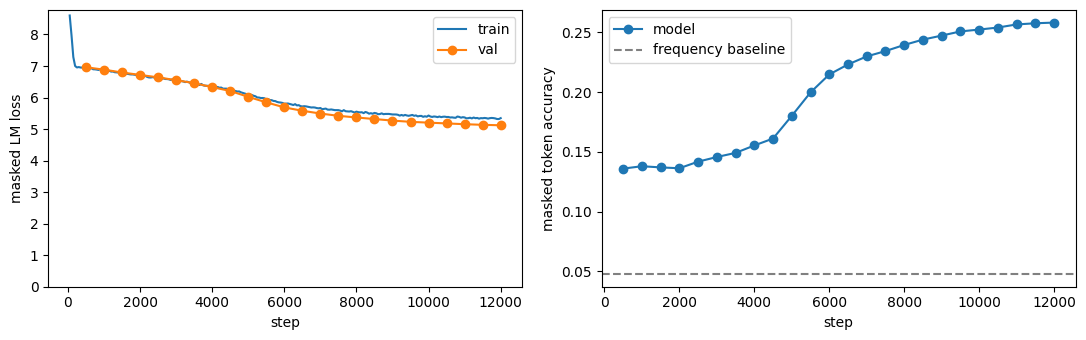

In [43]:
import matplotlib.pyplot as plt
tr = [h for h in history if "train_loss" in h]; va_ = [h for h in history if "val_loss" in h]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot([h["step"] for h in tr], [h["train_loss"] for h in tr], label="train")
ax[0].plot([h["step"] for h in va_], [h["val_loss"] for h in va_], label="val", marker="o")
ax[0].set_xlabel("step"); ax[0].set_ylabel("masked LM loss"); ax[0].legend(); ax[0].set_ylim(bottom=0)
ax[1].plot([h["step"] for h in va_], [h["val_acc"] for h in va_], marker="o", label="model")
ax[1].axhline(BASELINE_ACC, color="gray", ls="--", label="frequency baseline")
ax[1].set_xlabel("step"); ax[1].set_ylabel("masked token accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

## After the run

**Bundle for fine-tuning.** Keep `best.pt` and your `bpe.json` together (the checkpoint already stores `cfg` and `vocab_size`).

**Optional final phase at the full 2,048 context.** Most steps run at 512 for speed. To extend:
1. Set `seq_len=2048`, `micro_bs=16`, `max_steps` to the old value plus about 1,500, and `warmup_steps=100`.
2. Re-run the config cell and the cells from the model build onward. With `RESUME = True` it continues from `last.pt`. The positional table is fixed sin/cos, so nothing has to be learned for the longer length.

**Out of memory?** Lower `micro_bs`. `tokens_per_step` stays constant because gradient accumulation makes up the difference.